<a href="https://colab.research.google.com/github/rukshithadatla-0223/Bridge-load-distribution-calculator-/blob/main/Bridge_Load_distribution_calculator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Colab normally already has these, but this makes the notebook self-contained.
try:
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    !pip -q install ipywidgets
    import ipywidgets as widgets
    from IPython.display import display

In [5]:
def calculate_reactions(L, P1, x1, P2, x2):
    """
    L  = bridge span
    P1 = load 1 (downward)
    x1 = position of load 1 measured from left support
    P2 = load 2 (downward)
    x2 = position of load 2 measured from left support

    All forces use the same units, e.g. kN.
    """

    # Equilibrium equations:
    #
    # RA + RB = P1 + P2
    # 0*RA + L*RB = P1*x1 + P2*x2

    A = np.array([
        [1, 1],
        [0, L]
    ], dtype=float)

    b = np.array([
        P1 + P2,
        P1*x1 + P2*x2
    ], dtype=float)

    # Matrix inverse solution:
    reactions = np.linalg.inv(A) @ b

    RA, RB = reactions

    return A, b, RA, RB

FloatSlider(value=10.0, continuous_update=False, description='Span L:', max=20.0, min=5.0, step=0.5)

FloatSlider(value=20.0, continuous_update=False, description='Load P1:', step=1.0)

FloatSlider(value=4.0, continuous_update=False, description='Position x1:', max=9.5, min=0.5, step=0.5)

FloatSlider(value=10.0, continuous_update=False, description='Load P2:', step=1.0)

FloatSlider(value=7.0, continuous_update=False, description='Position x2:', max=9.5, min=0.5, step=0.5)

MATRIX CALCULATION
------------------
A =
[[ 1.  1.]
 [ 0. 10.]]

b =
[ 30. 150.]

A⁻¹ =
[[ 1.  -0.1]
 [ 0.   0.1]]

Reactions:
RA = 15.00
RB = 15.00

Equilibrium check:
RA + RB = 30.00  (total load = 30.00)
L × RB = 150.00  (load moments = 150.00)


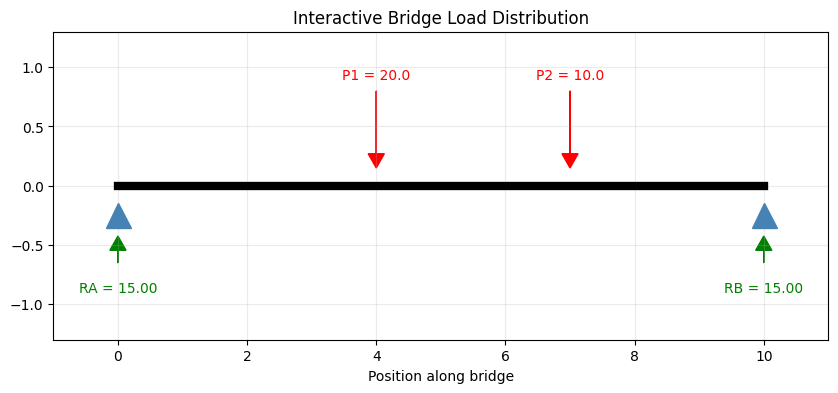

In [6]:
def show_bridge(L=10, P1=20, x1=4, P2=10, x2=7):

    A, b, RA, RB = calculate_reactions(L, P1, x1, P2, x2)

    print("MATRIX CALCULATION")
    print("------------------")
    print("A =")
    print(A)
    print("\nb =")
    print(b)

    print("\nA⁻¹ =")
    print(np.linalg.inv(A))

    print("\nReactions:")
    print(f"RA = {RA:.2f}")
    print(f"RB = {RB:.2f}")

    print("\nEquilibrium check:")
    print(f"RA + RB = {RA + RB:.2f}  "
          f"(total load = {P1 + P2:.2f})")

    print(f"L × RB = {L * RB:.2f}  "
          f"(load moments = {P1*x1 + P2*x2:.2f})")

    # -------------------------
    # Draw the bridge
    # -------------------------
    fig, ax = plt.subplots(figsize=(10, 4))

    # Beam
    ax.plot([0, L], [0, 0], color="black", linewidth=6)

    # Supports
    ax.plot(0, -0.25, "^", markersize=18, color="steelblue")
    ax.plot(L, -0.25, "^", markersize=18, color="steelblue")

    # Load arrows
    ax.arrow(
        x1, 0.8, 0, -0.65,
        head_width=0.25, head_length=0.12,
        length_includes_head=True, color="red"
    )
    ax.text(x1, 0.9, f"P1 = {P1:.1f}", ha="center", color="red")

    ax.arrow(
        x2, 0.8, 0, -0.65,
        head_width=0.25, head_length=0.12,
        length_includes_head=True, color="red"
    )
    ax.text(x2, 0.9, f"P2 = {P2:.1f}", ha="center", color="red")

    # Reaction arrows
    reaction_scale = max(P1 + P2, 1)

    ax.arrow(
        0, -0.65, 0, 0.45 * RA / reaction_scale,
        head_width=0.25, head_length=0.12,
        length_includes_head=True, color="green"
    )
    ax.text(0, -0.9, f"RA = {RA:.2f}", ha="center", color="green")

    ax.arrow(
        L, -0.65, 0, 0.45 * RB / reaction_scale,
        head_width=0.25, head_length=0.12,
        length_includes_head=True, color="green"
    )
    ax.text(L, -0.9, f"RB = {RB:.2f}", ha="center", color="green")

    ax.set_xlim(-1, L + 1)
    ax.set_ylim(-1.3, 1.3)
    ax.set_xlabel("Position along bridge")
    ax.set_title("Interactive Bridge Load Distribution")
    ax.grid(alpha=0.25)

    plt.show()


# Sliders
L_slider = widgets.FloatSlider(
    value=10, min=5, max=20, step=0.5,
    description="Span L:", continuous_update=False
)

P1_slider = widgets.FloatSlider(
    value=20, min=0, max=100, step=1,
    description="Load P1:", continuous_update=False
)

x1_slider = widgets.FloatSlider(
    value=4, min=0.5, max=9.5, step=0.5,
    description="Position x1:", continuous_update=False
)

P2_slider = widgets.FloatSlider(
    value=10, min=0, max=100, step=1,
    description="Load P2:", continuous_update=False
)

x2_slider = widgets.FloatSlider(
    value=7, min=0.5, max=9.5, step=0.5,
    description="Position x2:", continuous_update=False
)


def update_bridge(change=None):
    # Keep load positions inside the current span.
    x1_slider.max = max(0.5, L_slider.value - 0.5)
    x2_slider.max = max(0.5, L_slider.value - 0.5)

    show_bridge(
        L=L_slider.value,
        P1=P1_slider.value,
        x1=x1_slider.value,
        P2=P2_slider.value,
        x2=x2_slider.value
    )


for slider in [L_slider, P1_slider, x1_slider, P2_slider, x2_slider]:
    slider.observe(update_bridge, names="value")

display(L_slider, P1_slider, x1_slider, P2_slider, x2_slider)

update_bridge()